# 🧠 Proje 1 · Bölüm 2 — Klasik makine öğrenmesi: özellikleri biz tasarlarız
**Seviye: Orta**

Derin öğrenmeden önce yaygın olan yaklaşım şuydu:
1. Uzman (veya mühendis) görüntüden **ölçülebilir özellikler** çıkarır: ortalama parlaklık, doku pürüzlülüğü, kontrast…
2. Bu sayılar bir tabloya dönüşür (her satır bir hasta, her sütun bir özellik).
3. Klasik bir model (lojistik regresyon, karar ağacı, rastgele orman) bu tablodan öğrenir.

Bu yaklaşım **radyomiks (radiomics)** alanının temelidir ve hâlâ çok sayıda makalede kullanılır.

In [1]:
# Google Colab'da çalışıyorsanız: proje klasörünü (zip) yükleyip açın
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 01_Beyin_MR_Tumor.zip dosyasını seçin")
    yuklenen = files.upload()
    !unzip -q -o 01_Beyin_MR_Tumor.zip
    %cd 01_Beyin_MR_Tumor
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/01_Beyin_MR_Tumor


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
plt.rcParams["figure.dpi"] = 110

d = np.load("islenmis/veri_128.npz", allow_pickle=True)
X, y, bolum, gruplar = d["X"], d["y"], d["bolum"], d["grup"]
print(X.shape, "eğitim:", (bolum == "egitim").sum(), "test:", (bolum == "test").sum())

(253, 128, 128) eğitim: 202 test: 51


## 1. Görüntüden özellik çıkarma
Her görüntü için üç tür özellik hesaplayacağız:

| Özellik grubu | Ne anlatır? | Klinik benzetme |
|---|---|---|
| **Yoğunluk istatistikleri** (ortalama, std, çarpıklık, entropi) | Genel parlaklık ve dağılım | "Lezyon hiperintens mi?" |
| **GLCM doku özellikleri** (kontrast, homojenlik…) | Komşu pikseller ne kadar farklı? | "Heterojen kitle" |
| **LBP desenleri** | Küçük ölçekli doku desenleri | Mikro yapı |

In [3]:
def ozellik_cikar(x):
    g = (x * 255).astype(np.uint8)
    doku = g[g > 20]                                  # yalnızca beyin dokusu
    oz = {
        "ortalama": doku.mean(), "std": doku.std(),
        "carpiklik": stats.skew(doku), "basiklik": stats.kurtosis(doku),
        "p90": np.percentile(doku, 90), "p99": np.percentile(doku, 99),
        "parlak_oran": (doku > 180).mean(),
    }
    hist = np.histogram(doku, bins=32, range=(0, 256))[0] + 1e-9
    p = hist / hist.sum(); oz["entropi"] = -(p * np.log2(p)).sum()
    glcm = graycomatrix(g // 8, distances=[1, 3], angles=[0, np.pi / 2], levels=32, symmetric=True, normed=True)
    for ad in ["contrast", "homogeneity", "energy", "correlation", "dissimilarity"]:
        oz["glcm_" + ad] = graycoprops(glcm, ad).mean()
    lbp = local_binary_pattern(g, 8, 1, "uniform")
    lh = np.histogram(lbp[g > 20], bins=10, range=(0, 10), density=True)[0]
    for i, v in enumerate(lh):
        oz[f"lbp_{i}"] = v
    return oz

tablo = pd.DataFrame([ozellik_cikar(x) for x in X])
tablo["tumor"] = y
tablo.round(3).head()

,ortalama,std,carpiklik,basiklik,p90,p99,parlak_oran,entropi,glcm_contrast,glcm_homogeneity,...,lbp_1,lbp_2,lbp_3,lbp_4,lbp_5,lbp_6,lbp_7,lbp_8,lbp_9,tumor
0,120.868,51.030,0.417,0.044,208.0,240.00,0.144,4.421,14.467,0.536,...,0.089,0.059,0.115,0.243,0.132,0.064,0.066,0.060,0.112,1
1,112.288,58.320,0.099,-0.570,193.0,240.00,0.120,4.307,20.065,0.522,...,0.061,0.042,0.106,0.218,0.156,0.057,0.066,0.155,0.097,1
2,78.183,31.475,1.569,4.307,123.0,202.74,0.013,3.713,11.938,0.588,...,0.086,0.057,0.118,0.244,0.119,0.065,0.073,0.066,0.117,1
3,78.575,30.000,3.054,13.842,90.0,233.00,0.024,3.086,13.533,0.656,...,0.087,0.048,0.101,0.179,0.131,0.077,0.081,0.090,0.147,1
4,101.251,38.933,0.991,2.287,150.0,240.00,0.041,4.104,12.371,0.534,...,0.082,0.057,0.109,0.233,0.113,0.056,0.075,0.080,0.129,1


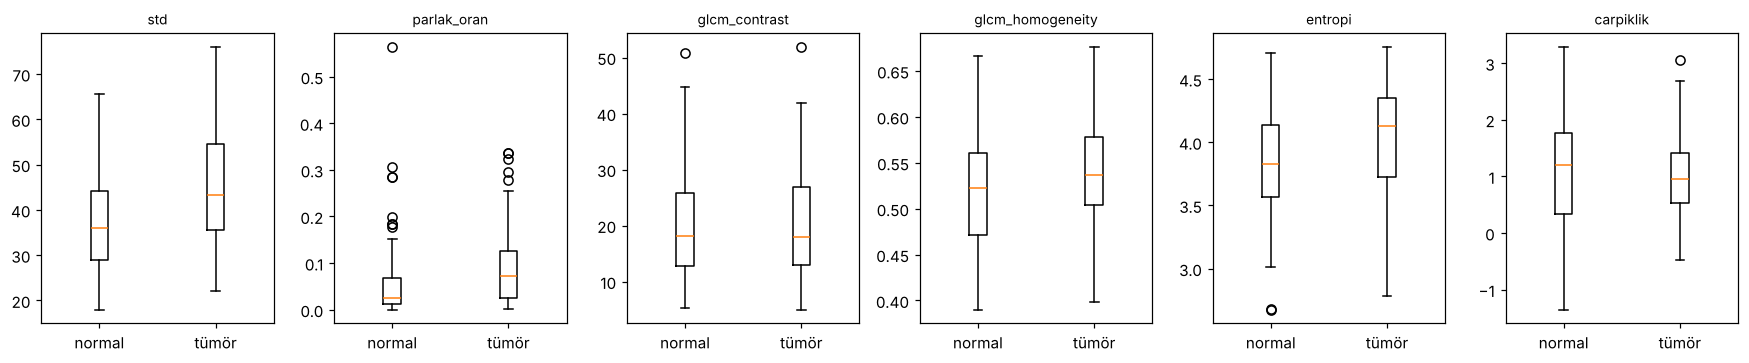

In [4]:
# Hangi özellik iki grubu en iyi ayırıyor? (kutu grafikleri)
sec = ["std", "parlak_oran", "glcm_contrast", "glcm_homogeneity", "entropi", "carpiklik"]
fig, axes = plt.subplots(1, len(sec), figsize=(16, 3.4))
for a, s in zip(axes, sec):
    a.boxplot([tablo.loc[tablo.tumor == 0, s], tablo.loc[tablo.tumor == 1, s]], tick_labels=["normal", "tümör"])
    a.set_title(s, fontsize=9)
plt.tight_layout(); plt.show()

## 2. Modelleri eğitelim ve **çapraz doğrulama** ile ölçelim
Az veri olduğunda tek bir bölünmeye güvenmek risklidir. **5 katlı çapraz doğrulama**: eğitim verisini 5 parçaya böl, her seferinde birini doğrulama için ayır, 5 sonucun ortalamasını al.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

oz_isim = [c for c in tablo.columns if c != "tumor"]
F = tablo[oz_isim].values
egt, tst = bolum == "egitim", bolum == "test"

modeller = {
    "Lojistik regresyon": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)),
    "k-En yakın komşu": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "Rastgele orman": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=0),
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
for ad, m in modeller.items():
    s = cross_val_score(m, F[egt], y[egt], groups=gruplar[egt], cv=cv, scoring="roc_auc")
    print(f"{ad:24s} AUC = {s.mean():.3f} ± {s.std():.3f}")

Lojistik regresyon       AUC = 0.866 ± 0.083
k-En yakın komşu         AUC = 0.721 ± 0.135


Rastgele orman           AUC = 0.861 ± 0.085


## 3. Test setinde değerlendirme — hekimin dilinde metrikler
| Metrik | Soru | Formül |
|---|---|---|
| **Duyarlılık (sensitivite)** | Tümörlü hastaların yüzde kaçını yakaladık? | DP / (DP + YN) |
| **Özgüllük (spesifite)** | Sağlamların yüzde kaçına "sağlam" dedik? | DN / (DN + YP) |
| **PPD** | "Tümör" dediklerimizin yüzde kaçı gerçekten tümör? | DP / (DP + YP) |
| **AUC** | Eşikten bağımsız genel ayırma gücü (0.5 = yazı-tura, 1 = mükemmel) | ROC eğrisi altındaki alan |

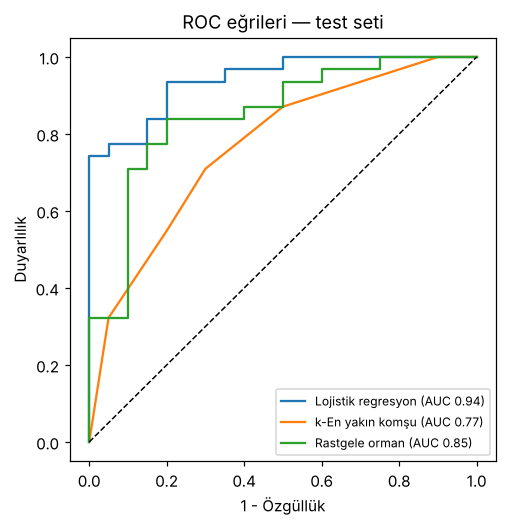

,AUC,Doğruluk,Duyarlılık,Özgüllük,PPD
Model,,,,,
Lojistik regresyon,0.942,0.843,0.839,0.85,0.897
k-En yakın komşu,0.769,0.706,0.903,0.40,0.700
Rastgele orman,0.850,0.765,0.935,0.50,0.744


In [6]:
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve

def rapor(y_gercek, olasilik, esik=0.5, ad=""):
    tahmin = (olasilik >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_gercek, tahmin).ravel()
    return {"Model": ad, "AUC": roc_auc_score(y_gercek, olasilik), "Doğruluk": (tp + tn) / len(y_gercek),
            "Duyarlılık": tp / (tp + fn), "Özgüllük": tn / (tn + fp), "PPD": tp / max(tp + fp, 1)}

sonuc = []; plt.figure(figsize=(5, 5))
for ad, m in modeller.items():
    m.fit(F[egt], y[egt]); p = m.predict_proba(F[tst])[:, 1]
    sonuc.append(rapor(y[tst], p, ad=ad))
    fpr, tpr, _ = roc_curve(y[tst], p); plt.plot(fpr, tpr, label=f"{ad} (AUC {sonuc[-1]['AUC']:.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("1 - Özgüllük"); plt.ylabel("Duyarlılık")
plt.title("ROC eğrileri — test seti"); plt.legend(fontsize=8); plt.show()
klasik = pd.DataFrame(sonuc).set_index("Model").round(3); klasik

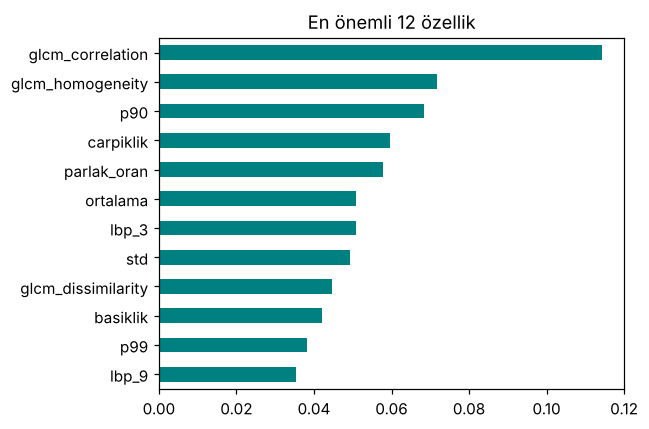

In [7]:
# Rastgele orman: hangi özellikler önemli?
rf = modeller["Rastgele orman"]
onem = pd.Series(rf.feature_importances_, index=oz_isim).sort_values()
onem.tail(12).plot.barh(figsize=(6, 4), color="teal"); plt.title("En önemli 12 özellik"); plt.tight_layout(); plt.show()
Path("islenmis").mkdir(exist_ok=True)
klasik.to_csv("islenmis/klasik_sonuclar.csv")

## ✅ Çıkarımlar
* Klasik yöntemler **yorumlanabilir**: hangi özelliğin önemli olduğunu görebiliyoruz.
* Ama özellikleri **biz** seçtik; tümörün şekli, yeri, kitle etkisi gibi bilgileri yakalamakta zorlanırlar.
* Bir sonraki bölümde, özellikleri **kendisi öğrenen** derin öğrenme (CNN) modelini deneyeceğiz ve sonuçları bu tabloyla karşılaştıracağız.

💡 **Araştırma fikri:** Aynı soruda radyomiks özellikleri + CNN özelliklerini birleştiren "hibrit" modeller, küçük veri setlerinde sıkça daha iyi sonuç verir.